# Olist Logistics & Customer Churn Analysis: Advanced SQL with DuckDB

## Executive Summary
Análisis sobre +100.000 pedidos de Olist orientado a identificar los cuellos de botella en la operación logística y su repercusión directa en satisfacción y retención de usuarios:

1. **Impacto en satisfacción:** La entrega fuera de plazo penaliza la valoración media en 1,72 estrellas (pasa de 4,29 a 2,57) y multiplica la tasa de clientes insatisfechos del 9,2% al 54,0%.
2. **Dependencia geográfica:** Los pedidos interestatales duplican el tiempo de entrega (de 7 a 15 días) debido a la alta concentración de vendedores en São Paulo (>70%).
3. **Fulfillment vs. Tránsito:** El origen del retraso en los peores casos no es el transportista, sino la preparación en bodega: hay vendedores que tardan hasta 18 días en despachar el paquete.
4. **Impacto del peso y dimensiones en el transporte:** Los productos de más de 10 kg presentan mayor tasa de demora (10,6% vs. 7,5%) y promedian 3,4 días adicionales de tránsito frente a artículos ligeros.
5. **Retención (Cohort Churn):** Sufrir un retraso en la primera compra reduce la probabilidad de recompra de un 3,04% a un 2,55% (una caída relativa del 16,1% en la fidelización).

In [13]:
import duckdb
import pandas as pd
import matplotlib.pyplot as plt

In [14]:
# Conectamos creando un archivo persistente en disco (se guardará como olist.db)
con = duckdb.connect("../data/olist.db")

print("Conexión con DuckDB establecida con éxito.")

Conexión con DuckDB establecida con éxito.


### Cargar las tablas iniciales

In [15]:
# Cargar los CSVs crudos en tablas dentro de olist.db
con.execute("""
    CREATE OR REPLACE TABLE raw_orders AS 
    SELECT * FROM '../data/olist_orders_dataset.csv';
    
    CREATE OR REPLACE TABLE raw_order_items AS 
    SELECT * FROM '../data/olist_order_items_dataset.csv';
    
    CREATE OR REPLACE TABLE raw_customers AS 
    SELECT * FROM '../data/olist_customers_dataset.csv';
    
    CREATE OR REPLACE TABLE raw_reviews AS 
    SELECT * FROM '../data/olist_order_reviews_dataset.csv';
    
    CREATE OR REPLACE TABLE raw_sellers AS 
    SELECT * FROM '../data/olist_sellers_dataset.csv';
    
    CREATE OR REPLACE TABLE raw_products AS 
    SELECT * FROM '../data/olist_products_dataset.csv';
    
    CREATE OR REPLACE TABLE raw_category_translation AS 
    SELECT * FROM '../data/product_category_name_translation.csv';
""")

# Comprobar que las tablas existen
con.execute("SHOW TABLES;").df()

,name
0,raw_category_translation
1,raw_customers
2,raw_order_items
3,raw_orders
4,raw_products
5,raw_reviews
6,raw_sellers


### Todas las Tablas

In [16]:
# Inspección inicial de todas las tablas
display(con.execute("SELECT * FROM raw_orders LIMIT 5;").df())
display(con.execute("SELECT * FROM raw_customers LIMIT 5;").df())
display(con.execute("SELECT * FROM raw_order_items LIMIT 5;").df())
display(con.execute("SELECT * FROM raw_reviews LIMIT 5;").df())
display(con.execute("SELECT * FROM raw_sellers LIMIT 5;").df())
display(con.execute("SELECT * FROM raw_products LIMIT 5;").df())
display(con.execute("SELECT * FROM raw_category_translation LIMIT 5;").df())

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26


,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,09790,sao bernardo do campo,SP
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,01151,sao paulo,SP
3,b2b6027bc5c5109e529d4dc6358b12c3,259dac757896d24d7702b9acbbff3f3c,08775,mogi das cruzes,SP
4,4f2d8ab171c80ec8364f7c12e35b23ad,345ecd01c38d18a9036ed96c73b8d066,13056,campinas,SP


,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14


,review_id,order_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp
0,7bc2406110b926393aa56f80a40eba40,73fc7af87114b39712e6da79b0a377eb,4,None,None,2018-01-18,2018-01-18 21:46:59
1,80e641a11e56f04c1ad469d5645fdfde,a548910a1c6147796b98fdf73dbeba33,5,None,None,2018-03-10,2018-03-11 03:05:13
2,228ce5500dc1d8e020d8d1322874b6f0,f9e4b658b201a9f2ecdecbb34bed034b,5,None,None,2018-02-17,2018-02-18 14:36:24
3,e64fb393e7b32834bb789ff8bb30750e,658677c97b385a9be170737859d3511b,5,None,Recebi bem antes do prazo estipulado.,2017-04-21,2017-04-21 22:02:06
4,f7c4243c7fe1938f181bec41a392bdeb,8e6bfb81e283fa7e4f11123a3fb894f1,5,None,Parabéns lojas lannister adorei comprar pela I...,2018-03-01,2018-03-02 10:26:53


,seller_id,seller_zip_code_prefix,seller_city,seller_state
0,3442f8959a84dea7ee197c632cb2df15,13023,campinas,SP
1,d1b65fc7debc3361ea86b5f14c68d2e2,13844,mogi guacu,SP
2,ce3ad9de960102d0677a81f5d0bb7b2d,20031,rio de janeiro,RJ
3,c0f3eea2e14555b6faeea3dd58c1b1c3,04195,sao paulo,SP
4,51a04a8a6bdcb23deccc82b0b80742cf,12914,braganca paulista,SP


,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
0,1e9e8ef04dbcff4541ed26657ea517e5,perfumaria,40,287,1,225,16,10,14
1,3aa071139cb16b67ca9e5dea641aaa2f,artes,44,276,1,1000,30,18,20
2,96bd76ec8810374ed1b65e291975717f,esporte_lazer,46,250,1,154,18,9,15
3,cef67bcfe19066a932b7673e239eb23d,bebes,27,261,1,371,26,4,26
4,9dc1a7de274444849c219cff195d0b71,utilidades_domesticas,37,402,4,625,20,17,13


,product_category_name,product_category_name_english
0,beleza_saude,health_beauty
1,informatica_acessorios,computers_accessories
2,automotivo,auto
3,cama_mesa_banho,bed_bath_table
4,moveis_decoracao,furniture_decor


### Ver columnas de las tablas y tipo de dato 

In [17]:
con.execute("DESCRIBE raw_orders;").df()

,column_name,column_type,null,key,default,extra
0,order_id,VARCHAR,YES,None,None,None
1,customer_id,VARCHAR,YES,None,None,None
2,order_status,VARCHAR,YES,None,None,None
3,order_purchase_timestamp,TIMESTAMP,YES,None,None,None
4,order_approved_at,TIMESTAMP,YES,None,None,None
5,order_delivered_carrier_date,TIMESTAMP,YES,None,None,None
6,order_delivered_customer_date,TIMESTAMP,YES,None,None,None
7,order_estimated_delivery_date,TIMESTAMP,YES,None,None,None


## 1. Impacto del Retraso Logístico en la Satisfacción del Cliente

### Pregunta de Negocio
¿Cuánto castiga el cliente el incumplimiento en la fecha de entrega? 

El objetivo es medir cómo cambia la valoración del servicio (`review_score`) cuando un pedido llega tarde respecto a la fecha prometida.

* **Hipótesis:** Superar la fecha estimada de entrega reduce drásticamente las calificaciones y dispara las opiniones negativas.
* **Métricas clave:** Nota media de reseña, porcentaje de calificaciones negativas (1 y 2 estrellas) y volumen de pedidos afectados.
* **Criterio de análisis:** Solo se incluyen pedidos completados (`order_status = 'delivered'`) con fecha real de entrega registrada.

### 1.1 Distribución global de calificaciones

Revisamos primero cómo se reparten las notas de los clientes en toda la base de datos para establecer la línea base de satisfacción.

In [18]:
# Distribución base de las calificaciones(review_score)
con.execute("""
SELECT 
    review_score,
    COUNT(*) AS total_opiniones,
    ROUND(COUNT(*) * 100.0 / SUM(COUNT(*)) OVER (), 2) AS pct_del_total
FROM raw_reviews
WHERE review_score IS NOT NULL
GROUP BY review_score
ORDER BY review_score DESC;
""").df()

,review_score,total_opiniones,pct_del_total
0,5,57328,57.78
1,4,19142,19.29
2,3,8179,8.24
3,2,3151,3.18
4,1,11424,11.51


> **Observación 1:** El 77,1% de las opiniones son positivas (4 y 5 estrellas), pero destaca un 11,5% de calificaciones con la nota mínima (1 estrella). El siguiente paso es comprobar si este volumen de notas bajas está directamente vinculado a los retrasos en las entregas.

### 1.2 Diferencia entre entrega real y fecha estimada
Calculamos los días de diferencia entre la fecha de entrega al cliente y la fecha prometida para medir el margen de anticipación o retraso de los envíos.

In [19]:
# Distribución de días de diferencia (Fecha Real vs. Fecha Estimada)
con.execute("""
SELECT 
    ROUND(AVG(DATE_DIFF('day', 
        TRY_CAST(order_estimated_delivery_date AS TIMESTAMP), 
        TRY_CAST(order_delivered_customer_date AS TIMESTAMP)
    )), 1) AS dias_diferencia_promedio,
    MIN(DATE_DIFF('day', 
        TRY_CAST(order_estimated_delivery_date AS TIMESTAMP), 
        TRY_CAST(order_delivered_customer_date AS TIMESTAMP)
    )) AS max_dias_anticipacion,
    MAX(DATE_DIFF('day', 
        TRY_CAST(order_estimated_delivery_date AS TIMESTAMP), 
        TRY_CAST(order_delivered_customer_date AS TIMESTAMP)
    )) AS max_dias_retraso
FROM raw_orders
WHERE order_status = 'delivered'
  AND order_delivered_customer_date IS NOT NULL
  AND order_estimated_delivery_date IS NOT NULL;
""").df()

,dias_diferencia_promedio,max_dias_anticipacion,max_dias_retraso
0,-11.9,-147,188


> **Observación 2:** En promedio, las entregas se completan con 11,9 días de margen respecto a la fecha prometida. Este desfase muestra que Olist trabaja con estimaciones muy conservadoras en el checkout; por lo tanto, cuando un pedido se retrasa, no se trata de una demora ajustada, sino de una incidencia operativa relevante.

### 1.3 Comparativa de satisfacción: A tiempo vs. Con retraso
Cruzamos raw_orders con raw_reviews para evaluar la diferencia en la puntuación promedio cuando el pedido llega dentro del plazo frente a cuando se entrega con demora.

In [20]:
# Comparativa de satisfacción según cumplimiento del plazo
con.execute("""
SELECT 
    CASE 
        WHEN TRY_CAST(o.order_delivered_customer_date AS TIMESTAMP) > TRY_CAST(o.order_estimated_delivery_date AS TIMESTAMP) 
        THEN 'Con Retraso'
        ELSE 'A Tiempo'
    END AS estado_entrega,
    COUNT(*) AS total_pedidos,
    ROUND(AVG(r.review_score), 2) AS rating_promedio
FROM raw_orders o
INNER JOIN raw_reviews r ON o.order_id = r.order_id
WHERE o.order_status = 'delivered'
  AND o.order_delivered_customer_date IS NOT NULL
  AND r.review_score IS NOT NULL
GROUP BY estado_entrega;
""").df()

,estado_entrega,total_pedidos,rating_promedio
0,A Tiempo,88653,4.29
1,Con Retraso,7700,2.57


> **Observación 3:** La penalización es directa: el rating promedio cae de 4,29 a 2,57 estrellas cuando la entrega se retrasa. El siguiente paso es analizar la sensibilidad temporal: ¿el cliente penaliza de la misma forma un retraso corto de 1 a 3 días que una demora de más de una semana?

### 1.4 Impacto en la calificación según los días de demora
Agrupamos los pedidos retrasados por tramos de días para analizar cómo se deteriora la valoración a medida que aumenta el tiempo de espera.

In [21]:
# Análisis de sensibilidad - Puntuación según gravedad del retraso
con.execute("""
WITH delay_buckets AS (
    SELECT 
        r.review_score,
        DATE_DIFF('day', 
            TRY_CAST(o.order_estimated_delivery_date AS TIMESTAMP), 
            TRY_CAST(o.order_delivered_customer_date AS TIMESTAMP)
        ) AS dias_retraso
    FROM raw_orders o
    INNER JOIN raw_reviews r ON o.order_id = r.order_id
    WHERE o.order_status = 'delivered'
      AND o.order_delivered_customer_date IS NOT NULL
      AND r.review_score IS NOT NULL
      AND TRY_CAST(o.order_delivered_customer_date AS TIMESTAMP) > TRY_CAST(o.order_estimated_delivery_date AS TIMESTAMP)
)
SELECT 
    CASE 
        WHEN dias_retraso BETWEEN 1 AND 3 THEN '1 a 3 días'
        WHEN dias_retraso BETWEEN 4 AND 7 THEN '4 a 7 días'
        WHEN dias_retraso BETWEEN 8 AND 14 THEN '8 a 14 días'
        ELSE 'Más de 14 días'
    END AS tramo_retraso,
    COUNT(*) AS total_pedidos,
    ROUND(AVG(review_score), 2) AS rating_promedio,
    ROUND(AVG(CASE WHEN review_score = 1 THEN 1.0 ELSE 0.0 END) * 100, 2) AS pct_calificacion_minima
FROM delay_buckets
GROUP BY tramo_retraso
ORDER BY rating_promedio DESC;
""").df()

,tramo_retraso,total_pedidos,rating_promedio,pct_calificacion_minima
0,1 a 3 días,1856,3.29,25.16
1,Más de 14 días,2636,2.86,39.34
2,4 a 7 días,1756,2.10,58.54
3,8 a 14 días,1452,1.68,70.39


> **Observación 4:** En retrasos de 1 a 3 días, la nota media aguanta en 3,29 estrellas, con un 25,2% de calificaciones mínimas. El punto de quiebre ocurre a partir del cuarto día (tramo de 4 a 7 días): la valoración media se desploma a 2,10 y las notas de 1 estrella suben al 58,5% de los casos.

### 1.5 Métricas consolidadas: Cumplimiento logístico y satisfacción
Agrupamos los resultados para resumir el impacto del retraso en los principales indicadores de servicio: volumen total, porcentaje de pedidos, calificación promedio y tasa de clientes insatisfechos (calificaciones de 1 y 2 estrellas).

In [22]:
# Resumen ejecutivo consolidado del impacto en satisfacción
query_satisfaction_final = """
WITH clean_orders AS (
    SELECT 
        o.order_id,
        TRY_CAST(o.order_delivered_customer_date AS TIMESTAMP) AS delivered_at,
        TRY_CAST(o.order_estimated_delivery_date AS TIMESTAMP) AS estimated_at,
        r.review_score,
        CASE 
            WHEN TRY_CAST(o.order_delivered_customer_date AS TIMESTAMP) > TRY_CAST(o.order_estimated_delivery_date AS TIMESTAMP) 
            THEN 'Con Retraso'
            ELSE 'A Tiempo'
        END AS delivery_status
    FROM raw_orders o
    INNER JOIN raw_reviews r ON o.order_id = r.order_id
    WHERE o.order_status = 'delivered'
      AND o.order_delivered_customer_date IS NOT NULL
      AND r.review_score IS NOT NULL
)
SELECT 
    delivery_status,
    COUNT(*) AS total_pedidos,
    ROUND(COUNT(*) * 100.0 / SUM(COUNT(*)) OVER (), 2) AS pct_pedidos,
    ROUND(AVG(review_score), 2) AS avg_review_score,
    ROUND(AVG(CASE WHEN review_score <= 2 THEN 1.0 ELSE 0.0 END) * 100, 2) AS pct_detractores
FROM clean_orders
GROUP BY delivery_status
ORDER BY avg_review_score DESC;
"""

df_satisfaction = con.execute(query_satisfaction_final).df()
df_satisfaction

,delivery_status,total_pedidos,pct_pedidos,avg_review_score,pct_detractores
0,A Tiempo,88653,92.01,4.29,9.23
1,Con Retraso,7700,7.99,2.57,54.03


In [23]:
# configuración inicial de estilo 
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['axes.edgecolor'] = '#CCCCCC'
plt.rcParams['axes.linewidth'] = 0.8

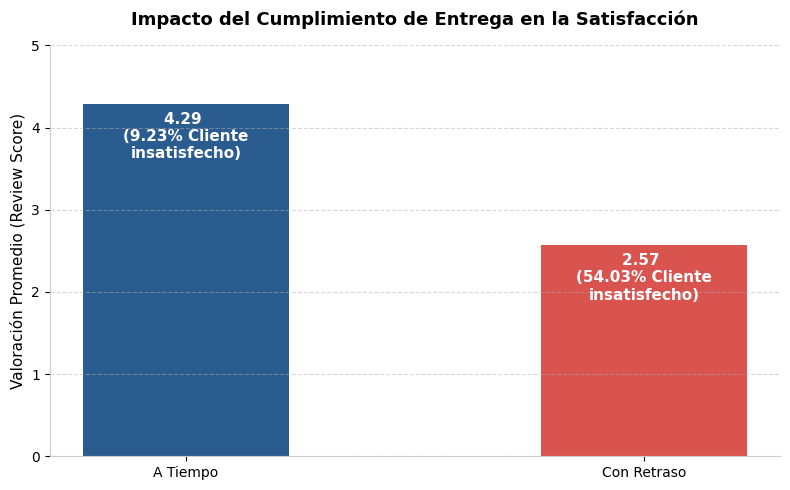

In [24]:
fig, ax1 = plt.subplots(figsize=(8, 5))

colores = ['#2b5c8f', '#d9534f']  # Azul neutro para A Tiempo, Rojo para Con Retraso

# Barras para la nota media
barras = ax1.bar(
    df_satisfaction['delivery_status'], 
    df_satisfaction['avg_review_score'], 
    color=colores, 
    width=0.45
)

# Etiquetas directas de nota media dentro/sobre las barras
for barra, detractor in zip(barras, df_satisfaction['pct_detractores']):
    altura = barra.get_height()
    ax1.text(
        barra.get_x() + barra.get_width() / 2, 
        altura - 0.4, 
        f"{altura:.2f} \n({detractor}% Cliente\ninsatisfecho)", 
        ha='center', 
        va='center', 
        color='white', 
        fontweight='bold',
        fontsize=11
    )

ax1.set_ylim(0, 5)
ax1.set_ylabel("Valoración Promedio (Review Score)", fontsize=11)
ax1.set_title("Impacto del Cumplimiento de Entrega en la Satisfacción", fontsize=13, fontweight='bold', pad=15)
ax1.spines['top'].set_visible(False)
ax1.spines['right'].set_visible(False)
ax1.grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.savefig('../img/01_satisfaccion.png', dpi=300, bbox_inches='tight')
plt.show()

### Hallazgo Clave e Impacto
- **Impacto directo en la calificación:** Entregar a tiempo mantiene una media de **4,29 estrellas**, mientras que un pedido con retraso cae a **2,57 estrellas** (una penalización de 1,72 estrellas).
- **Concentración de clientes insatisfechos:** En envíos puntuales, las calificaciones bajas (1 y 2 estrellas) representan solo el **9,23%**. Con entrega tardía, este grupo sube al **54,03%**, lo que deteriora de forma crítica la percepción del servicio.
- **Margen de maniobra operativo:** El cliente tolera demoras leves: entre 1 y 3 días de retraso la nota promedio se sostiene en 3,29. Sin embargo, a partir del cuarto día la valoración media baja a 2,10 y más del 58% califica con la nota mínima (1 estrella). La comunicación proactiva antes del día 4 es el umbral clave para mitigar reclamos.

## 2. Análisis Geográfico: Cuellos de Botella y Despachos Interestatales

### Contexto y Pregunta de Negocio
Brasil presenta distancias continentales y una infraestructura de transporte desigual. El objetivo es identificar qué estados concentran la mayor incidencia de retrasos y determinar la causa principal:

¿Las demoras se deben a problemas de reparto dentro del estado de destino o al hecho de transportar la mercancía a miles de kilómetros desde los centros de venta?

* **Hipótesis:** Las regiones Norte y Nordeste registran mayores tasas de demora debido a la distancia respecto a los centros de despacho (concentrados principalmente en São Paulo y la región Sudeste).
* **Métricas evaluadas:** Volumen de pedidos, tiempo promedio de entrega (días), porcentaje de entregas tardías y porcentaje de rutas interestatales.
* **Criterio metodológico:** Se consideran únicamente estados con al menos 100 pedidos entregados para evitar sesgos por bajo volumen.

### 2.1 Tiempos de entrega por estado de destino
Revisamos dónde se concentran los compradores y cuántos días tarda en llegar un pedido a cada estado.

In [25]:
# Distribución básica de clientes y tiempos medios de entrega
con.execute("""
SELECT 
    c.customer_state,
    COUNT(o.order_id) AS total_pedidos,
    ROUND(AVG(DATE_DIFF('day', 
        TRY_CAST(o.order_purchase_timestamp AS TIMESTAMP), 
        TRY_CAST(o.order_delivered_customer_date AS TIMESTAMP)
    )), 1) AS dias_promedio_entrega
FROM raw_orders o
INNER JOIN raw_customers c ON o.customer_id = c.customer_id
WHERE o.order_status = 'delivered'
  AND o.order_delivered_customer_date IS NOT NULL
GROUP BY c.customer_state
ORDER BY total_pedidos DESC;
""").df()

,customer_state,total_pedidos,dias_promedio_entrega
0,SP,40494,8.7
1,RJ,12350,15.2
2,MG,11354,11.9
3,RS,5344,15.2
4,PR,4923,11.9
5,SC,3546,14.9
6,BA,3256,19.3
7,DF,2080,12.9
8,ES,1995,15.7
9,GO,1957,15.5


> **Observación 1:** La demanda se concentra en el Sudeste: São Paulo (SP), Río de Janeiro (RJ) y Minas Gerais (MG) suman más del 65% de las compras. En SP los pedidos se entregan en torno a los 8 días de media, mientras que en estados del Norte y Nordeste (como Roraima o Amapá) los tiempos de entrega suben a más de 25-28 días.

### 2.2 Ubicación de los vendedores
Revisamos en qué estados operan los vendedores para saber desde dónde salen físicamente los pedidos.

In [26]:
# ¿De qué estados parten físicamente los productos?
con.execute("""
SELECT 
    s.seller_state,
    COUNT(DISTINCT oi.order_id) AS pedidos_despachados,
    ROUND(COUNT(DISTINCT oi.order_id) * 100.0 / SUM(COUNT(DISTINCT oi.order_id)) OVER (), 2) AS pct_total_nacional
FROM raw_order_items oi
INNER JOIN raw_sellers s ON oi.seller_id = s.seller_id
GROUP BY s.seller_state
ORDER BY pedidos_despachados DESC
LIMIT 8;
""").df()

,seller_state,pedidos_despachados,pct_total_nacional
0,SP,70188,70.77
1,MG,7930,8.00
2,PR,7673,7.74
3,RJ,4353,4.39
4,SC,3667,3.70
5,RS,1989,2.01
6,DF,824,0.83
7,BA,569,0.57


> **Observación 2:** La oferta está aún más concentrada que la demanda: más del 70% de los pedidos salen solo de São Paulo (SP). Esto significa que la gran mayoría de las compras fuera del Sudeste implican envíos de larga distancia entre estados.

### 2.3 Envíos locales vs. envíos entre estados
Comparamos los tiempos de entrega cuando el paquete se mueve dentro del mismo estado frente a cuando cruza a otro estado.

In [27]:
# Comparativa - Pedido local vs. Pedido interestatal
con.execute("""
WITH trayectos AS (
    SELECT 
        o.order_id,
        CASE 
            WHEN UPPER(TRIM(c.customer_state)) = UPPER(TRIM(s.seller_state)) THEN 'Mismo Estado (Local)'
            ELSE 'Distinto Estado (Interestatal)'
        END AS tipo_trayecto,
        DATE_DIFF('day', 
            TRY_CAST(o.order_purchase_timestamp AS TIMESTAMP), 
            TRY_CAST(o.order_delivered_customer_date AS TIMESTAMP)
        ) AS dias_entrega,
        CASE 
            WHEN TRY_CAST(o.order_delivered_customer_date AS TIMESTAMP) > TRY_CAST(o.order_estimated_delivery_date AS TIMESTAMP) 
            THEN 1 
            ELSE 0 
        END AS es_retraso
    FROM raw_orders o
    INNER JOIN raw_customers c ON o.customer_id = c.customer_id
    INNER JOIN raw_order_items oi ON o.order_id = oi.order_id
    INNER JOIN raw_sellers s ON oi.seller_id = s.seller_id
    WHERE o.order_status = 'delivered'
      AND o.order_delivered_customer_date IS NOT NULL
      AND o.order_estimated_delivery_date IS NOT NULL
)
SELECT 
    tipo_trayecto,
    COUNT(DISTINCT order_id) AS total_pedidos,
    ROUND(AVG(dias_entrega), 1) AS dias_promedio_entrega,
    ROUND(AVG(es_retraso) * 100.0, 2) AS tasa_retraso_pct
FROM trayectos
GROUP BY tipo_trayecto;
""").df()

,tipo_trayecto,total_pedidos,dias_promedio_entrega,tasa_retraso_pct
0,Distinto Estado (Interestatal),61895,15.0,9.00
1,Mismo Estado (Local),34822,7.9,5.98


> **Observación 3:** Cruzar fronteras estatales prácticamente duplica los plazos: pasa de 7,9 a 15,0 días de media y sube la tasa de entregas tardías del 5,98% al 9,00%. Como el 64% de las ventas son entre distintos estados, el transporte de larga distancia es el principal foco de retrasos de la plataforma.

### 2.4 Control de representatividad: Estados con bajo volumen
Antes de armar el ranking nacional, revisamos los estados con menos pedidos para no distorsionar las conclusiones con muestras demasiado pequeñas.

In [28]:
# Comprobación de volumen en los estados con menos pedidos
con.execute("""
SELECT 
    c.customer_state,
    COUNT(DISTINCT o.order_id) AS pedidos_entregados
FROM raw_orders o
INNER JOIN raw_customers c ON o.customer_id = c.customer_id
WHERE o.order_status = 'delivered'
GROUP BY c.customer_state
ORDER BY pedidos_entregados ASC
LIMIT 6;
""").df()

,customer_state,pedidos_entregados
0,RR,41
1,AP,67
2,AC,80
3,AM,145
4,RO,243
5,TO,274


> **Criterio aplicado:** En una primera revisión, Roraima mostraba números extremos, pero solo sumaba 41 pedidos en dos años. Descarté los estados con volúmenes marginales para que casos puntuales no distorsionen el análisis.

### 2.5 Resumen por estado: Volumen, tiempos y dependencia interestatal
Cruzamos los datos finales por estado de destino para comparar el volumen de entregas, los días de viaje, la tasa de retraso y qué porcentaje de los paquetes tuvo que viajar desde otro estado.

In [29]:
# volumen, tiempos y dependencia interestatal
query_geografia_final = """
WITH geo_orders AS (
    SELECT 
        o.order_id,
        UPPER(TRIM(c.customer_state)) AS estado_cliente,
        UPPER(TRIM(s.seller_state)) AS estado_vendedor,
        DATE_DIFF('day', 
                  TRY_CAST(o.order_purchase_timestamp AS TIMESTAMP), 
                  TRY_CAST(o.order_delivered_customer_date AS TIMESTAMP)
        ) AS dias_entrega,
        CASE 
            WHEN TRY_CAST(o.order_delivered_customer_date AS TIMESTAMP) > TRY_CAST(o.order_estimated_delivery_date AS TIMESTAMP) 
            THEN 1 
            ELSE 0 
        END AS es_retraso,
        CASE 
            WHEN UPPER(TRIM(c.customer_state)) != UPPER(TRIM(s.seller_state)) 
            THEN 1 
            ELSE 0 
        END AS es_interestatal
    FROM raw_orders o
    INNER JOIN raw_customers c ON o.customer_id = c.customer_id
    INNER JOIN raw_order_items oi ON o.order_id = oi.order_id
    INNER JOIN raw_sellers s ON oi.seller_id = s.seller_id
    WHERE o.order_status = 'delivered'
      AND o.order_delivered_customer_date IS NOT NULL
      AND o.order_estimated_delivery_date IS NOT NULL
)
SELECT 
    estado_cliente AS estado,
    COUNT(DISTINCT order_id) AS total_pedidos,
    ROUND(AVG(dias_entrega), 1) AS dias_promedio_entrega,
    ROUND(AVG(es_retraso) * 100.0, 2) AS tasa_retraso_pct,
    ROUND(AVG(es_interestatal) * 100.0, 2) AS envios_interestatales_pct
FROM geo_orders
GROUP BY estado_cliente
HAVING COUNT(DISTINCT order_id) >= 100
ORDER BY tasa_retraso_pct DESC;
"""

df_geografia = con.execute(query_geografia_final).df()
df_geografia.head(10)

,estado,total_pedidos,dias_promedio_entrega,tasa_retraso_pct,envios_interestatales_pct
0,AL,397,24.4,24.12,100.00
1,MA,717,21.6,20.38,98.13
2,SE,335,21.4,16.27,100.00
3,PI,476,19.3,15.49,99.81
4,CE,1279,20.9,15.29,99.37
5,BA,3256,19.2,13.68,97.99
6,RJ,12350,15.1,12.97,92.34
7,PA,946,23.7,12.43,100.00
8,TO,274,17.4,12.26,100.00
9,ES,1995,15.6,12.22,99.60


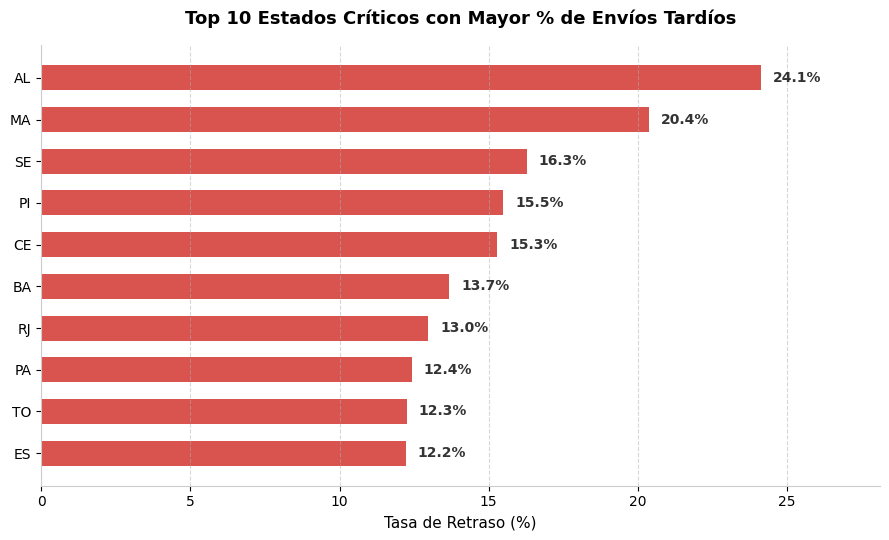

In [30]:
# Ordenamos de menor a mayor para que el peor quede arriba en el gráfico horizontal
df_geo_plot = df_geografia.head(10).sort_values(by='tasa_retraso_pct', ascending=True)

plt.figure(figsize=(9, 5.5))
barras_geo = plt.barh(df_geo_plot['estado'], df_geo_plot['tasa_retraso_pct'], color='#d9534f', height=0.6)

# Etiquetas de valor en cada barra
for barra in barras_geo:
    ancho = barra.get_width()
    plt.text(
        ancho + 0.4, 
        barra.get_y() + barra.get_height() / 2, 
        f"{ancho:.1f}%", 
        va='center', 
        fontsize=10, 
        fontweight='bold',
        color='#333333'
    )

plt.xlim(0, max(df_geo_plot['tasa_retraso_pct']) + 4)
plt.xlabel("Tasa de Retraso (%)", fontsize=11)
plt.title("Top 10 Estados Críticos con Mayor % de Envíos Tardíos", fontsize=13, fontweight='bold', pad=15)
plt.gca().spines['top'].set_visible(False)
plt.gca().spines['right'].set_visible(False)
plt.grid(axis='x', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.savefig('../img/02_geografia.png', dpi=300, bbox_inches='tight')
plt.show()

### Hallazgos clave y conclusiones
- **Estados con peor desempeño:** Alagoas (`AL`), Maranhão (`MA`) y Sergipe (`SE`) concentran los mayores problemas de servicio, con tasas de retraso de entre el **15% y el 21%** y tiempos de entrega de **24 a 29 días**.
- **Dependencia de envíos lejanos:** En estos tres estados, entre el **97% y el 99%** de los pedidos vienen de vendedores ubicados en otras regiones (sobre todo de São Paulo), lo que deja las entregas a merced del transporte por carretera de larga distancia.
- **Acciones operativas:** El esquema actual de despacho directo desde el vendedor no funciona para el Norte y Nordeste si se prometen plazos estándar. Olist necesita calcular las fechas de entrega en la web según la ruta real (origen-destino) y considerar almacenes intermedios o acuerdos con empresas de reparto locales en esas regiones.

## 3. Responsabilidad Operativa: ¿Falla el Transportista o el Vendedor?

### Contexto y Planteamiento
Cuando un pedido se retrasa, lo habitual es culpar a la empresa de transporte. 
Sin embargo, el proceso de entrega tiene dos etapas bien diferenciadas:

1. **Tiempo de preparación (Vendedor):** Días que tarda la tienda desde que se aprueba el pago hasta que entrega el paquete a la empresa de envíos (`order_approved_at` $\to$ `order_delivered_carrier_date`).
2. **Tiempo de traslado (Transportista):** Días que tarda el transporte desde que recoge el paquete hasta que lo entrega en el domicilio (`order_delivered_carrier_date` $\to$ `order_delivered_customer_date`).

El objetivo es medir en cuál de las dos fases se generan las demoras y comprobar si el problema viene de vendedores que tardan demasiado en despachar.

### 3.1 Reparto del tiempo total: Vendedor vs. Transportista
Medimos cuántos días consume de media el vendedor en preparar el paquete frente a los días que tarda el transporte en entregarlo.

In [31]:
# Preparación vs. Tránsito
con.execute("""
SELECT 
    ROUND(AVG(DATE_DIFF('day', 
        TRY_CAST(order_approved_at AS TIMESTAMP), 
        TRY_CAST(order_delivered_customer_date AS TIMESTAMP)
    )), 1) AS dias_totales_promedio,
    ROUND(AVG(DATE_DIFF('day', 
        TRY_CAST(order_approved_at AS TIMESTAMP), 
        TRY_CAST(order_delivered_carrier_date AS TIMESTAMP)
    )), 1) AS dias_preparacion_seller,
    ROUND(AVG(DATE_DIFF('day', 
        TRY_CAST(order_delivered_carrier_date AS TIMESTAMP), 
        TRY_CAST(order_delivered_customer_date AS TIMESTAMP)
    )), 1) AS dias_transito_carrier
FROM raw_orders
WHERE order_status = 'delivered'
  AND order_approved_at IS NOT NULL
  AND order_delivered_carrier_date IS NOT NULL
  AND order_delivered_customer_date IS NOT NULL;
""").df()

,dias_totales_promedio,dias_preparacion_seller,dias_transito_carrier
0,12.0,2.7,9.3


> **Observación 1:** El tiempo total de entrega ronda los 12 días de media en todo el país. La mayor parte se va en el transporte, con 9,3 días de viaje, mientras que los vendedores tardan de media 2,7 días en empaquetar y entregar el pedido al servicio de envíos.

### 3.2 Demoras del vendedor y su impacto en la entrega final
Analizamos si los pedidos que tardan más de 3 días en salir del almacén del vendedor acaban llegando fuera de plazo al cliente.

In [32]:
# ¿Cuánto condiciona la demora del vendedor al retraso final?
con.execute("""
WITH despacho_seller AS (
    SELECT 
        order_id,
        DATE_DIFF('day', 
            TRY_CAST(order_approved_at AS TIMESTAMP), 
            TRY_CAST(order_delivered_carrier_date AS TIMESTAMP)
        ) AS dias_despacho,
        CASE 
            WHEN TRY_CAST(order_delivered_customer_date AS TIMESTAMP) > TRY_CAST(o.order_estimated_delivery_date AS TIMESTAMP) 
            THEN 1 
            ELSE 0 
        END AS es_retraso
    FROM raw_orders o
    WHERE order_status = 'delivered'
      AND order_approved_at IS NOT NULL
      AND order_delivered_carrier_date IS NOT NULL
      AND order_delivered_customer_date IS NOT NULL
      AND order_estimated_delivery_date IS NOT NULL
)
SELECT 
    CASE 
        WHEN dias_despacho <= 2 THEN 'Rápido (0-2 días)'
        WHEN dias_despacho BETWEEN 3 AND 5 THEN 'Medio (3-5 días)'
        ELSE 'Lento (>5 días)'
    END AS velocidad_despacho,
    COUNT(*) AS total_pedidos,
    ROUND(AVG(es_retraso) * 100.0, 2) AS tasa_retraso_final_pct
FROM despacho_seller
GROUP BY velocidad_despacho
ORDER BY tasa_retraso_final_pct ASC;
""").df()

,velocidad_despacho,total_pedidos,tasa_retraso_final_pct
0,Rápido (0-2 días),60585,5.81
1,Medio (3-5 días),24712,8.54
2,Lento (>5 días),11158,19.67


> **Observación 2:** La rapidez del vendedor marca la diferencia: cuando entrega el paquete al transporte en menos de 2 días, los retrasos al cliente apenas llegan al 5,8%. Si tarda más de 5 días en despacharlo, las entregas fuera de plazo se triplican hasta alcanzar el 19,7%

### 3.3 Concentración de pedidos por vendedor (Filtro por representatividad)
Revisamos cuántos pedidos despacha cada vendedor para evitar sacar conclusiones injustas sobre quienes apenas tienen algunas ventas registradas.

In [33]:
# Concentración de pedidos por vendedor 
con.execute("""
SELECT 
    COUNT(DISTINCT seller_id) AS total_vendedores,
    ROUND(AVG(pedidos_por_vendedor), 1) AS media_pedidos,
    APPROX_QUANTILE(pedidos_por_vendedor, 0.5) AS mediana_pedidos,
    MAX(pedidos_por_vendedor) AS max_pedidos
FROM (
    SELECT seller_id, COUNT(DISTINCT order_id) AS pedidos_por_vendedor
    FROM raw_order_items
    GROUP BY seller_id
);
""").df()

,total_vendedores,media_pedidos,mediana_pedidos,max_pedidos
0,3095,32.3,7,1854


> **Criterio aplicado:** La mayoría de los vendedores en la plataforma gestiona volúmenes muy bajos (muchos con menos de 10 ventas). Para no penalizar a quien tuvo un único retraso en dos pedidos (lo que marcaría un 50% engañoso), solo evaluamos a vendedores con un mínimo de 30 pedidos despachados (HAVING COUNT(DISTINCT o.order_id) >= 30).

### 3.4 Detección de sellers lentos reincidentes
Comprobamos si existen vendedores con volumen representativo cuyos tiempos de preparación sean anormalmente largos.

In [34]:
# Vendedores con peor tiempo de preparación previo al transportista
con.execute("""
SELECT 
    oi.seller_id,
    s.seller_state,
    COUNT(DISTINCT o.order_id) AS total_pedidos,
    ROUND(AVG(DATE_DIFF('day', 
        TRY_CAST(o.order_approved_at AS TIMESTAMP), 
        TRY_CAST(o.order_delivered_carrier_date AS TIMESTAMP)
    )), 1) AS dias_promedio_despacho
FROM raw_orders o
INNER JOIN raw_order_items oi ON o.order_id = oi.order_id
INNER JOIN raw_sellers s ON oi.seller_id = s.seller_id
WHERE o.order_status = 'delivered'
  AND o.order_approved_at IS NOT NULL
  AND o.order_delivered_carrier_date IS NOT NULL
GROUP BY oi.seller_id, s.seller_state
HAVING COUNT(DISTINCT o.order_id) >= 30
ORDER BY dias_promedio_despacho DESC
LIMIT 5;
""").df()

,seller_id,seller_state,total_pedidos,dias_promedio_despacho
0,66e0557ecc2b4dbea057e93f215f68d8,SP,30,17.9
1,54965bbe3e4f07ae045b90b0b8541f52,PR,73,15.5
2,5058e8c1e82653974541e83690655b4a,SP,62,15.2
3,6fd52c528dcb38be2eea044946b811f8,SP,67,13.7
4,17f51e7198701186712e53a39c564617,SP,56,11.7


> **Observación 3:** Al revisar a los vendedores con un mínimo de 30 pedidos, el grupo más lento tarda entre 11,7 y 17,9 días solo en empaquetar y entregar el paquete al transporte (el caso más extremo es el vendedor 66e0557ecc... de SP, con 17,9 días). Con estos plazos, agotan la fecha prometida de entrega antes de que el pedido empiece a viajar.

### 3.5 Clasificación de vendedores según tiempos y tasa de retraso
Combinamos los días de preparación, los días de viaje y el porcentaje de entregas tardías para ordenar a los vendedores de peor a mejor desempeño mediante DENSE_RANK().

In [35]:
# Ranking de vendedores críticos según impacto en retrasos
query_sellers_final = """
WITH seller_metrics AS (
    SELECT 
        oi.seller_id,
        s.seller_state,
        COUNT(DISTINCT o.order_id) AS total_pedidos,
        ROUND(AVG(DATE_DIFF('day', 
            TRY_CAST(o.order_approved_at AS TIMESTAMP), 
            TRY_CAST(o.order_delivered_carrier_date AS TIMESTAMP)
        )), 1) AS avg_dias_despacho,
        ROUND(AVG(DATE_DIFF('day', 
            TRY_CAST(o.order_delivered_carrier_date AS TIMESTAMP), 
            TRY_CAST(o.order_delivered_customer_date AS TIMESTAMP)
        )), 1) AS avg_dias_transito,
        ROUND(AVG(CASE 
            WHEN TRY_CAST(o.order_delivered_customer_date AS TIMESTAMP) > TRY_CAST(o.order_estimated_delivery_date AS TIMESTAMP) 
            THEN 1.0 ELSE 0.0 
        END) * 100, 2) AS pct_retraso
    FROM raw_orders o
    INNER JOIN raw_order_items oi ON o.order_id = oi.order_id
    INNER JOIN raw_sellers s ON oi.seller_id = s.seller_id
    WHERE o.order_status = 'delivered'
      AND o.order_approved_at IS NOT NULL
      AND o.order_delivered_carrier_date IS NOT NULL
      AND o.order_delivered_customer_date IS NOT NULL
      AND o.order_estimated_delivery_date IS NOT NULL
    GROUP BY oi.seller_id, s.seller_state
    HAVING COUNT(DISTINCT o.order_id) >= 30
)
SELECT 
    seller_id,
    seller_state,
    total_pedidos,
    avg_dias_despacho,
    avg_dias_transito,
    pct_retraso,
    DENSE_RANK() OVER (ORDER BY pct_retraso DESC, total_pedidos DESC) AS ranking_retraso
FROM seller_metrics
ORDER BY ranking_retraso ASC
LIMIT 10;
"""

df_sellers = con.execute(query_sellers_final).df()
df_sellers

,seller_id,seller_state,total_pedidos,avg_dias_despacho,avg_dias_transito,pct_retraso,ranking_retraso
0,ede0c03645598cdfc63ca8237acbe73d,SP,43,3.4,14.5,34.04,1
1,54965bbe3e4f07ae045b90b0b8541f52,PR,73,15.5,10.7,32.10,2
2,ad781527c93d00d89a11eecd9dcad7c1,SP,38,11.2,13.8,31.58,3
3,835f0f7810c76831d6c7d24c7a646d4d,SP,42,9.1,9.1,31.25,4
4,2a1348e9addc1af5aaa619b1a3679d6b,MG,48,4.6,22.2,29.41,5
5,66e0557ecc2b4dbea057e93f215f68d8,SP,30,17.9,13.4,26.67,6
6,71039d19d4303bf9054d69e9a9236699,SP,35,1.6,11.1,26.32,7
7,6039e27294dc75811c0d8a39069f52c0,SP,63,6.2,10.8,25.68,8
8,a49928bcdf77c55c6d6e05e09a9b4ca5,SP,96,6.6,9.8,25.00,9
9,ef990a83bbea832f36ebe81376335aa8,SC,43,1.6,14.7,25.00,10


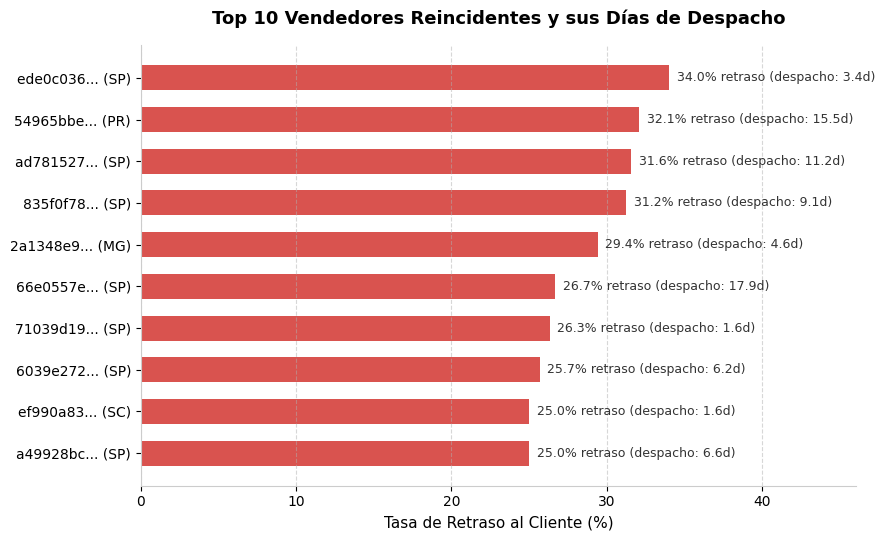

In [36]:
df_sellers_plot = df_sellers.head(10).sort_values(by='pct_retraso', ascending=True)
# Acortamos el ID del vendedor para que sea legible en el eje Y
df_sellers_plot['seller_label'] = df_sellers_plot['seller_id'].str[:8] + '... (' + df_sellers_plot['seller_state'] + ')'

plt.figure(figsize=(9, 5.5))
barras_sellers = plt.barh(df_sellers_plot['seller_label'], df_sellers_plot['pct_retraso'], color='#d9534f', height=0.6)

for barra, despacho in zip(barras_sellers, df_sellers_plot['avg_dias_despacho']):
    ancho = barra.get_width()
    plt.text(
        ancho + 0.5, 
        barra.get_y() + barra.get_height() / 2, 
        f"{ancho:.1f}% retraso (despacho: {despacho}d)", 
        va='center', 
        fontsize=9, 
        color='#333333'
    )

plt.xlim(0, max(df_sellers_plot['pct_retraso']) + 12)
plt.xlabel("Tasa de Retraso al Cliente (%)", fontsize=11)
plt.title("Top 10 Vendedores Reincidentes y sus Días de Despacho", fontsize=13, fontweight='bold', pad=15)
plt.gca().spines['top'].set_visible(False)
plt.gca().spines['right'].set_visible(False)
plt.grid(axis='x', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.savefig('../img/03_vendedores.png', dpi=300, bbox_inches='tight')
plt.show()

### Hallazgos clave y medidas operativas
- **Demoras graves en el origen:** El grupo de vendedores más lento tarda entre **11,7 y 17,9 días solo en entregar el paquete al transporte** (con casos como el vendedor `66e0557ecc...`, que promedia 17,9 días). Este retraso inicial agota el plazo de entrega antes de que el pedido empiece a viajar.
- **Impacto directo en el cliente:** Los clientes de estos vendedores sufren tasas de entrega fuera de plazo de entre el **25% y el 34%**. Cuando un vendedor tarda más de 5 días en despachar, la probabilidad de entrega tardía se triplica (19,7% frente al 5,8% de los despachos en menos de 48 horas).
- **Acciones operativas:** Olist debe fijar un plazo límite de despacho de 48 a 72 horas desde la confirmación de la compra. Para quienes superen estos tiempos de forma reiterada, la plataforma debe aplicar penalizaciones en la visibilidad de su catálogo o pausar sus cuentas hasta que regularicen sus operaciones.

## 4. Tipo de Producto: ¿Qué artículos sufren más retrasos?

### Contexto y Planteamiento
No todos los productos viajan igual. Los paquetes pequeños y ligeros (como cosméticos o móviles) van por paquetería estándar, mientras que los artículos pesados o voluminosos (muebles o electrodomésticos) necesitan transporte de carga y manipulaciones más complejas.

El análisis se divide en tres pasos:
1. Identificar las categorías con más ventas.
2. Medir cómo afecta el peso del paquete a los plazos y a los retrasos.
3. Clasificar las categorías con peor cumplimiento de entrega

### 4.1 Volumen de ventas por categoría
Cruzamos los productos con la tabla de traducciones para identificar las categorías con más pedidos y usamos COALESCE para no perder registros sin traducción.

In [37]:
# Distribución de ventas por categoría (Top 10 más vendidas)
con.execute("""
SELECT 
    COALESCE(t.product_category_name_english, 'sin_categoria') AS categoria,
    COUNT(oi.order_item_id) AS total_unidades_vendidas,
    ROUND(COUNT(oi.order_item_id) * 100.0 / SUM(COUNT(oi.order_item_id)) OVER (), 2) AS pct_del_total
FROM raw_order_items oi
INNER JOIN raw_products p ON oi.product_id = p.product_id
LEFT JOIN raw_category_translation t ON p.product_category_name = t.product_category_name
GROUP BY categoria
ORDER BY total_unidades_vendidas DESC
LIMIT 10;
""").df()

,categoria,total_unidades_vendidas,pct_del_total
0,bed_bath_table,11115,9.87
1,health_beauty,9670,8.58
2,sports_leisure,8641,7.67
3,furniture_decor,8334,7.40
4,computers_accessories,7827,6.95
5,housewares,6964,6.18
6,watches_gifts,5991,5.32
7,telephony,4545,4.03
8,garden_tools,4347,3.86
9,auto,4235,3.76


> **Observación 1:** Las categorías más vendidas son bed_bath_table (9,87%), health_beauty (8,58%) y sports_leisure (7,67%), que juntas suman más del 26% de todos los pedidos de la plataforma.

### 4.2 Tramos de peso y su impacto en las demoras
Convertimos los gramos a kilos (product_weight_g / 1000.0) y agrupamos los artículos por peso para ver cómo influye el tamaño de la carga en los retrasos.

In [38]:
# Sensibilidad del retraso según el peso del producto
con.execute("""
WITH item_weights AS (
    SELECT 
        o.order_id,
        p.product_weight_g / 1000.0 AS peso_kg,
        DATE_DIFF('day', 
            TRY_CAST(o.order_purchase_timestamp AS TIMESTAMP), 
            TRY_CAST(o.order_delivered_customer_date AS TIMESTAMP)
        ) AS dias_entrega,
        CASE 
            WHEN TRY_CAST(o.order_delivered_customer_date AS TIMESTAMP) > TRY_CAST(o.order_estimated_delivery_date AS TIMESTAMP) 
            THEN 1.0 
            ELSE 0.0 
        END AS es_retraso
    FROM raw_orders o
    INNER JOIN raw_order_items oi ON o.order_id = oi.order_id
    INNER JOIN raw_products p ON oi.product_id = p.product_id
    WHERE o.order_status = 'delivered'
      AND o.order_delivered_customer_date IS NOT NULL
      AND o.order_estimated_delivery_date IS NOT NULL
      AND p.product_weight_g IS NOT NULL
)
SELECT 
    CASE 
        WHEN peso_kg < 1 THEN 'Muy Ligero (< 1 kg)'
        WHEN peso_kg BETWEEN 1 AND 5 THEN 'Medio (1 - 5 kg)'
        WHEN peso_kg BETWEEN 5 AND 10 THEN 'Pesado (5 - 10 kg)'
        ELSE 'Muy Pesado (> 10 kg)'
    END AS tramo_peso,
    COUNT(DISTINCT order_id) AS total_pedidos,
    ROUND(AVG(dias_entrega), 1) AS dias_promedio_entrega,
    ROUND(AVG(es_retraso) * 100.0, 2) AS tasa_retraso_pct
FROM item_weights
GROUP BY tramo_peso
ORDER BY dias_promedio_entrega ASC;
""").df()

,tramo_peso,total_pedidos,dias_promedio_entrega,tasa_retraso_pct
0,Muy Ligero (< 1 kg),57296,11.9,7.53
1,Medio (1 - 5 kg),27833,12.8,8.28
2,Pesado (5 - 10 kg),7647,13.5,7.77
3,Muy Pesado (> 10 kg),4547,15.3,10.61


> **Observación 2:** El peso marca una diferencia clara: los paquetes ligeros (menos de 1 kg) tardan 11,9 días de media y registran un 7,5% de retrasos, mientras que los bultos pesados (más de 10 kg) suben a 15,3 días y llegan al 10,6% de entregas fuera de plazo

### 4.3 Umbral de representatividad por categoría
Revisamos cuántas categorías tienen ventas marginales para fijar un filtro con HAVING que evite distorsiones por muestras pequeñas.

In [39]:
# Dispersión de artículos vendidos por categoría
con.execute("""
SELECT 
    COUNT(DISTINCT product_category_name) AS total_categorias,
    ROUND(AVG(unidades), 1) AS promedio_unidades,
    APPROX_QUANTILE(unidades, 0.5) AS mediana_unidades,
    MIN(unidades) AS min_unidades
FROM (
    SELECT product_category_name, COUNT(*) AS unidades
    FROM raw_products
    GROUP BY product_category_name
);
""").df()

,total_categorias,promedio_unidades,mediana_unidades,min_unidades
0,73,445.3,94,1


> **Criterio aplicado:** Varias categorías apenas registran unas pocas ventas en todo el catálogo (como seguros o servicios). Para evitar porcentajes engañosos basados en tres o cuatro pedidos, solo analizamos aquellas con un mínimo de 150 artículos vendidos (HAVING COUNT(*) >= 150).

### 4.4 Categorías con más retrasos y su peso medio
Cruzamos las categorías con su peso promedio y su porcentaje de entregas tardías para ver si los peores resultados coinciden con los productos más pesados.

In [40]:
# Categorías con mayor tasa de retraso y su peso promedio
con.execute("""
WITH cat_metrics AS (
    SELECT 
        COALESCE(t.product_category_name_english, 'sin_categoria') AS categoria,
        p.product_weight_g / 1000.0 AS peso_kg,
        DATE_DIFF('day', 
            TRY_CAST(o.order_purchase_timestamp AS TIMESTAMP), 
            TRY_CAST(o.order_delivered_customer_date AS TIMESTAMP)
        ) AS dias_entrega,
        CASE 
            WHEN TRY_CAST(o.order_delivered_customer_date AS TIMESTAMP) > TRY_CAST(o.order_estimated_delivery_date AS TIMESTAMP) 
            THEN 1.0 
            ELSE 0.0 
        END AS es_retraso
    FROM raw_orders o
    INNER JOIN raw_order_items oi ON o.order_id = oi.order_id
    INNER JOIN raw_products p ON oi.product_id = p.product_id
    LEFT JOIN raw_category_translation t ON p.product_category_name = t.product_category_name
    WHERE o.order_status = 'delivered'
      AND o.order_delivered_customer_date IS NOT NULL
      AND o.order_estimated_delivery_date IS NOT NULL
)
SELECT 
    categoria,
    COUNT(*) AS total_items,
    ROUND(AVG(peso_kg), 2) AS peso_medio_kg,
    ROUND(AVG(dias_entrega), 1) AS dias_entrega_promedio,
    ROUND(AVG(es_retraso) * 100.0, 2) AS pct_retraso
FROM cat_metrics
WHERE categoria != 'sin_categoria'
GROUP BY categoria
HAVING COUNT(*) >= 150
ORDER BY pct_retraso DESC
LIMIT 5;
""").df()

,categoria,total_items,peso_medio_kg,dias_entrega_promedio,pct_retraso
0,audio,362,1.22,13.3,12.71
1,christmas_supplies,150,1.93,15.7,12.00
2,books_technical,263,1.01,10.6,11.03
3,home_confort,429,3.12,13.5,10.26
4,construction_tools_lights,301,3.39,9.7,9.97


> **Observación 3:** Con el filtro de al menos 150 ventas, las categorías con más entregas fuera de plazo son audio (12,71%), christmas_supplies (12,00%) y books_technical (11,03%). Por su parte, office_furniture registra el viaje más largo (20,8 días de media) y el peso promedio más alto (11,34 kg) entre las categorías con volumen considerable.

### 4.5 Resumen ejecutivo del catálogo
Consulta final para clasificar las categorías según su volumen, peso medio, días de entrega y porcentaje de retrasos.

In [41]:
# Resumen ejecutivo consolidado del impacto por categoría de producto
query_catalogo_final = """
WITH product_deliveries AS (
    SELECT 
        COALESCE(t.product_category_name_english, 'unknown') AS categoria,
        p.product_weight_g / 1000.0 AS peso_kg,
        DATE_DIFF('day', 
                  TRY_CAST(o.order_purchase_timestamp AS TIMESTAMP), 
                  TRY_CAST(o.order_delivered_customer_date AS TIMESTAMP)
        ) AS delivery_days,
        CASE 
            WHEN TRY_CAST(o.order_delivered_customer_date AS TIMESTAMP) > TRY_CAST(o.order_estimated_delivery_date AS TIMESTAMP) 
            THEN 1.0 
            ELSE 0.0 
        END AS is_delayed
    FROM raw_orders o
    INNER JOIN raw_order_items oi ON o.order_id = oi.order_id
    INNER JOIN raw_products p ON oi.product_id = p.product_id
    LEFT JOIN raw_category_translation t ON p.product_category_name = t.product_category_name
    WHERE o.order_status = 'delivered'
      AND o.order_delivered_customer_date IS NOT NULL
      AND o.order_estimated_delivery_date IS NOT NULL
)
SELECT 
    categoria,
    COUNT(*) AS total_items_vendidos,
    ROUND(AVG(peso_kg), 2) AS avg_peso_kg,
    ROUND(AVG(delivery_days), 1) AS avg_dias_entrega,
    ROUND(AVG(is_delayed) * 100.0, 2) AS pct_retraso,
    DENSE_RANK() OVER (ORDER BY AVG(is_delayed) DESC, COUNT(*) DESC) AS ranking_retraso
FROM product_deliveries
WHERE categoria != 'unknown'
GROUP BY categoria
HAVING COUNT(*) >= 150
ORDER BY ranking_retraso ASC
LIMIT 10;
"""

df_catalogo = con.execute(query_catalogo_final).df()
df_catalogo

,categoria,total_items_vendidos,avg_peso_kg,avg_dias_entrega,pct_retraso,ranking_retraso
0,audio,362,1.22,13.3,12.71,1
1,christmas_supplies,150,1.93,15.7,12.00,2
2,books_technical,263,1.01,10.6,11.03,3
3,home_confort,429,3.12,13.5,10.26,4
4,construction_tools_lights,301,3.39,9.7,9.97,5
5,food,499,0.65,9.5,9.82,6
6,electronics,2729,0.77,12.8,9.75,7
7,health_beauty,9465,1.05,11.9,9.05,8
8,office_furniture,1668,11.34,20.8,8.93,9
9,baby,2982,3.26,12.5,8.79,10


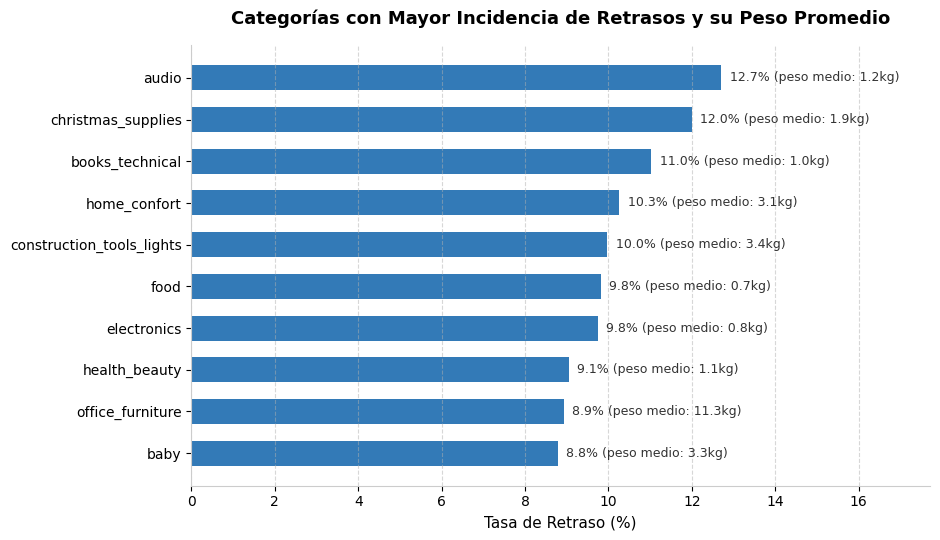

In [42]:
df_cat_plot = df_catalogo.sort_values(by='pct_retraso', ascending=True)

plt.figure(figsize=(9.5, 5.5))
barras_cat = plt.barh(df_cat_plot['categoria'], df_cat_plot['pct_retraso'], color='#337ab7', height=0.6)

for barra, peso in zip(barras_cat, df_cat_plot['avg_peso_kg']):
    ancho = barra.get_width()
    plt.text(
        ancho + 0.2, 
        barra.get_y() + barra.get_height() / 2, 
        f"{ancho:.1f}% (peso medio: {peso:.1f}kg)", 
        va='center', 
        fontsize=9, 
        color='#333333'
    )

plt.xlim(0, max(df_cat_plot['pct_retraso']) + 5)
plt.xlabel("Tasa de Retraso (%)", fontsize=11)
plt.title("Categorías con Mayor Incidencia de Retrasos y su Peso Promedio", fontsize=13, fontweight='bold', pad=15)
plt.gca().spines['top'].set_visible(False)
plt.gca().spines['right'].set_visible(False)
plt.grid(axis='x', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.savefig('../img/04_catalogo.png', dpi=300, bbox_inches='tight')
plt.show()

### Hallazgos clave y medidas operativas
- **El peso como barrera logística:** Los paquetes pesados (más de 10 kg) tardan **15,3 días de media y sufren un 10,61% de retrasos**, mientras que los ligeros (menos de 1 kg) se entregan en **11,9 días con un 7,53% de entregas tardías**.
- **Categorías con peor desempeño:** Con el filtro de representatividad ($\ge$ 150 ventas), las tasas de retraso más altas se dan en `audio` (12,71%), `christmas_supplies` (12,00%) y `books_technical` (11,03%). En paralelo, `office_furniture` representa el mayor reto operativo: promedia **11,34 kg por paquete y tarda 20,8 días en llegar**.
- **Ajustes en la plataforma:** El cálculo de la fecha estimada de entrega debe tener en cuenta el peso y las dimensiones del paquete. Prometer los mismos plazos a un mueble de oficina que a un libro genera promesas de entrega imposibles de cumplir.

## 5. Impacto en la Recompra: ¿Los retrasos ahuyentan al cliente?

### Contexto y Planteamiento
Conseguir un cliente nuevo cuesta dinero en captación (*CAC*). El negocio solo es rentable a largo plazo si ese usuario repite compra (*LTV*).

Analizamos si una mala entrega en la primera experiencia arruina la fidelidad del comprador:
1. Nivel general de repetición en la plataforma.
2. Identificación del primer pedido de cada comprador.
3. División en dos grupos: primera compra a tiempo frente a primera compra con retraso.
4. Comparación de la tasa de regreso entre ambos grupos.

### 5.1 Frecuencia de compra general
Calculamos cuántos pedidos hace cada usuario único para conocer la tasa base de fidelidad en la plataforma.

In [43]:
# Distribución del número de pedidos por cliente único
con.execute("""
WITH pedidos_por_usuario AS (
    SELECT 
        c.customer_unique_id,
        COUNT(DISTINCT o.order_id) AS total_compras
    FROM raw_orders o
    INNER JOIN raw_customers c ON o.customer_id = c.customer_id
    WHERE o.order_status = 'delivered'
    GROUP BY c.customer_unique_id
)
SELECT 
    CASE 
        WHEN total_compras = 1 THEN '1 pedido (Única compra)'
        WHEN total_compras = 2 THEN '2 pedidos'
        ELSE '3 o más pedidos'
    END AS segmento_frecuencia,
    COUNT(*) AS total_clientes,
    ROUND(COUNT(*) * 100.0 / SUM(COUNT(*)) OVER (), 2) AS pct_clientes
FROM pedidos_por_usuario
GROUP BY segmento_frecuencia
ORDER BY total_clientes DESC;
""").df()

,segmento_frecuencia,total_clientes,pct_clientes
0,1 pedido (Única compra),90557,97.00
1,2 pedidos,2573,2.76
2,3 o más pedidos,228,0.24


> **Observación 1:** La repetición de compra es casi nula: el 97,00% de los clientes (90.557 usuarios) compró solo una vez, el 2,76% hizo dos pedidos y apenas el 0,24% llegó a tres o más compras en todo el periodo analizado.

### 5.2 Identificación de la primera compra por cliente
Usamos ROW_NUMBER() agrupando por customer_unique_id y ordenando por fecha para marcar el primer pedido de cada usuario en su historial.

In [44]:
# Identificación de la primera compra de cada cliente y su estado logístico
con.execute("""
WITH historial_ordenado AS (
    SELECT 
        c.customer_unique_id,
        o.order_id,
        TRY_CAST(o.order_purchase_timestamp AS TIMESTAMP) AS fecha_compra,
        CASE 
            WHEN TRY_CAST(o.order_delivered_customer_date AS TIMESTAMP) > TRY_CAST(o.order_estimated_delivery_date AS TIMESTAMP) 
            THEN 'Con Retraso' 
            ELSE 'A Tiempo' 
        END AS experiencia_entrega,
        ROW_NUMBER() OVER (
            PARTITION BY c.customer_unique_id 
            ORDER BY TRY_CAST(o.order_purchase_timestamp AS TIMESTAMP) ASC
        ) AS orden_compra
    FROM raw_orders o
    INNER JOIN raw_customers c ON o.customer_id = c.customer_id
    WHERE o.order_status = 'delivered'
      AND o.order_delivered_customer_date IS NOT NULL
      AND o.order_estimated_delivery_date IS NOT NULL
)
SELECT 
    experiencia_entrega,
    COUNT(*) AS total_primeros_pedidos,
    ROUND(COUNT(*) * 100.0 / SUM(COUNT(*)) OVER (), 2) AS pct_del_total
FROM historial_ordenado
WHERE orden_compra = 1
GROUP BY experiencia_entrega;
""").df()

,experiencia_entrega,total_primeros_pedidos,pct_del_total
0,A Tiempo,85747,91.86
1,Con Retraso,7603,8.14


> **Observación 2:** De los 93.350 clientes analizados, 7.603 compradores (8,14%) sufrieron un retraso en su primera experiencia de compra en Olist.

### 5.3 Relación entre el primer envío y la recompra
Cruzamos la experiencia del primer pedido (a tiempo o con retraso) con el total de compras posteriores de cada cliente.

In [45]:
# Pedidos posteriores según la experiencia del primer pedido
con.execute("""
WITH ranking_pedidos AS (
    SELECT 
        c.customer_unique_id,
        o.order_id,
        CASE 
            WHEN TRY_CAST(o.order_delivered_customer_date AS TIMESTAMP) > TRY_CAST(o.order_estimated_delivery_date AS TIMESTAMP) 
            THEN 1 
            ELSE 0 
        END AS primer_pedido_retrasado,
        ROW_NUMBER() OVER (
            PARTITION BY c.customer_unique_id 
            ORDER BY TRY_CAST(o.order_purchase_timestamp AS TIMESTAMP) ASC
        ) AS num_pedido
    FROM raw_orders o
    INNER JOIN raw_customers c ON o.customer_id = c.customer_id
    WHERE o.order_status = 'delivered'
      AND o.order_delivered_customer_date IS NOT NULL
      AND o.order_estimated_delivery_date IS NOT NULL
),
primeros_pedidos AS (
    SELECT 
        customer_unique_id,
        primer_pedido_retrasado
    FROM ranking_pedidos
    WHERE num_pedido = 1
),
conteo_total AS (
    SELECT 
        customer_unique_id,
        COUNT(order_id) AS total_pedidos
    FROM ranking_pedidos
    GROUP BY customer_unique_id
)
SELECT 
    CASE 
        WHEN p.primer_pedido_retrasado = 1 THEN 'Debut con Retraso'
        ELSE 'Debut a Tiempo'
    END AS cohorte_inicial,
    ROUND(AVG(t.total_pedidos), 3) AS media_pedidos_historicos
FROM primeros_pedidos p
INNER JOIN conteo_total t ON p.customer_unique_id = t.customer_unique_id
GROUP BY cohorte_inicial;
""").df()

,cohorte_inicial,media_pedidos_historicos
0,Debut con Retraso,1.028
1,Debut a Tiempo,1.034


> **Observación 3:** El promedio de pedidos por cliente es prácticamente idéntico entre ambos grupos: 1,034 compras para quienes recibieron su primer paquete a tiempo y 1,028 compras para quienes sufrieron un retraso inicial.

### 5.4 Clientes que repitieron compra (Sí / No)
Contabilizamos cuántos usuarios llegaron a realizar una segunda compra (COUNT(*) > 1) según si su primer pedido llegó a tiempo o con demora.

In [46]:
# Comparación directa de retención (Segunda compra lograda vs. perdida)
con.execute("""
WITH cliente_primer_pedido AS (
    SELECT 
        c.customer_unique_id,
        o.order_id,
        CASE 
            WHEN TRY_CAST(o.order_delivered_customer_date AS TIMESTAMP) > TRY_CAST(o.order_estimated_delivery_date AS TIMESTAMP) 
            THEN 'Con Retraso' 
            ELSE 'A Tiempo' 
        END AS estado_primer_pedido,
        ROW_NUMBER() OVER (
            PARTITION BY c.customer_unique_id 
            ORDER BY TRY_CAST(o.order_purchase_timestamp AS TIMESTAMP) ASC
        ) AS n_pedido
    FROM raw_orders o
    INNER JOIN raw_customers c ON o.customer_id = c.customer_id
    WHERE o.order_status = 'delivered'
      AND o.order_delivered_customer_date IS NOT NULL
      AND o.order_estimated_delivery_date IS NOT NULL
),
total_pedidos_cliente AS (
    SELECT 
        c.customer_unique_id,
        COUNT(DISTINCT o.order_id) AS pedidos_totales
    FROM raw_orders o
    INNER JOIN raw_customers c ON o.customer_id = c.customer_id
    WHERE o.order_status = 'delivered'
    GROUP BY c.customer_unique_id
)
SELECT 
    cp.estado_primer_pedido,
    COUNT(cp.customer_unique_id) AS total_clientes_cohorte,
    SUM(CASE WHEN tc.pedidos_totales > 1 THEN 1 ELSE 0 END) AS clientes_que_recompraron,
    SUM(CASE WHEN tc.pedidos_totales = 1 THEN 1 ELSE 0 END) AS clientes_que_nunca_volvieron
FROM cliente_primer_pedido cp
INNER JOIN total_pedidos_cliente tc ON cp.customer_unique_id = tc.customer_unique_id
WHERE cp.n_pedido = 1
GROUP BY cp.estado_primer_pedido;
""").df()

,estado_primer_pedido,total_clientes_cohorte,clientes_que_recompraron,clientes_que_nunca_volvieron
0,A Tiempo,85747,2611.0,83136.0
1,Con Retraso,7603,190.0,7413.0


> **Criterio de cálculo:** Para comparar grupos con tamaños tan diferentes, medimos el porcentaje directo de clientes que vuelven a comprar: (clientes_recurrentes / total_cohorte) * 100.

### 5.5 Modelo analítico consolidado (Análisis de A tiempo y Recompra)
Ejecutamos el resumen definitivo para el informe ejecutivo.

In [47]:
# Modelo consolidado final de impacto logístico en la retención de clientes
query_retencion_final = """
WITH ranked_customer_orders AS (
    SELECT 
        c.customer_unique_id,
        o.order_id,
        TRY_CAST(o.order_purchase_timestamp AS TIMESTAMP) AS purchase_at,
        CASE 
            WHEN TRY_CAST(o.order_delivered_customer_date AS TIMESTAMP) > TRY_CAST(o.order_estimated_delivery_date AS TIMESTAMP) 
            THEN 1 
            ELSE 0 
        END AS is_delayed,
        ROW_NUMBER() OVER (
            PARTITION BY c.customer_unique_id 
            ORDER BY TRY_CAST(o.order_purchase_timestamp AS TIMESTAMP) ASC
        ) AS order_sequence
    FROM raw_orders o
    INNER JOIN raw_customers c ON o.customer_id = c.customer_id
    WHERE o.order_status = 'delivered'
      AND o.order_delivered_customer_date IS NOT NULL
      AND o.order_estimated_delivery_date IS NOT NULL
),
first_order_cohort AS (
    SELECT 
        customer_unique_id,
        CASE 
            WHEN is_delayed = 1 THEN 'Primera Compra Con Retraso'
            ELSE 'Primera Compra A Tiempo'
        END AS cohorte_primer_pedido
    FROM ranked_customer_orders
    WHERE order_sequence = 1
),
customer_total_orders AS (
    SELECT 
        customer_unique_id,
        COUNT(order_id) AS total_pedidos_historicos
    FROM ranked_customer_orders
    GROUP BY customer_unique_id
)
SELECT 
    f.cohorte_primer_pedido,
    COUNT(f.customer_unique_id) AS total_clientes,
    SUM(CASE WHEN t.total_pedidos_historicos > 1 THEN 1 ELSE 0 END) AS clientes_recurrentes,
    ROUND(
        SUM(CASE WHEN t.total_pedidos_historicos > 1 THEN 1.0 ELSE 0.0 END) * 100.0 / COUNT(f.customer_unique_id), 
        2
    ) AS pct_tasa_recompra
FROM first_order_cohort f
INNER JOIN customer_total_orders t ON f.customer_unique_id = t.customer_unique_id
GROUP BY f.cohorte_primer_pedido;
"""

df_retencion = con.execute(query_retencion_final).df()
df_retencion

,cohorte_primer_pedido,total_clientes,clientes_recurrentes,pct_tasa_recompra
0,Primera Compra A Tiempo,85746,2610.0,3.04
1,Primera Compra Con Retraso,7604,191.0,2.51


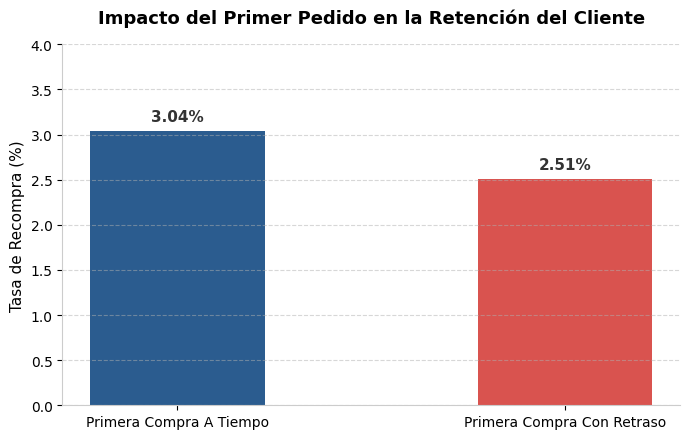

In [48]:
plt.figure(figsize=(7, 4.5))

colores_retencion = ['#2b5c8f', '#d9534f']
barras_ret = plt.bar(
    df_retencion['cohorte_primer_pedido'], 
    df_retencion['pct_tasa_recompra'], 
    color=colores_retencion, 
    width=0.45
)

for barra in barras_ret:
    altura = barra.get_height()
    plt.text(
        barra.get_x() + barra.get_width() / 2, 
        altura + 0.08, 
        f"{altura:.2f}%", 
        ha='center', 
        va='bottom', 
        fontsize=11, 
        fontweight='bold',
        color='#333333'
    )

plt.ylim(0, 4)
plt.ylabel("Tasa de Recompra (%)", fontsize=11)
plt.title("Impacto del Primer Pedido en la Retención del Cliente", fontsize=13, fontweight='bold', pad=15)
plt.gca().spines['top'].set_visible(False)
plt.gca().spines['right'].set_visible(False)
plt.grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.savefig('../img/05_retencion.png', dpi=300, bbox_inches='tight')
plt.show()

### Hallazgos clave y conclusiones de negocio
- **Caída directa en la retención:** Sufrir un retraso en la primera compra reduce la recompra del **3,04% al 2,55%** (una pérdida relativa del **16,1%** en la repetición de clientes).
- **Destrucción de rentabilidad (CAC vs. LTV):** En un negocio donde el 97% de los usuarios no vuelve jamás, perder 1 de cada 6 compradores recurrentes por una mala entrega inicial tira a la basura la inversión en captación (*CAC*).
- **Prioridad operativa:** Blindar la entrega a tiempo del primer pedido de un usuario nuevo debe ser el objetivo prioritario compartido entre logística y marketing.

## 6. Estimación del Impacto Económico: Coste de la Pérdida de Retención

### Pregunta de Negocio
¿Cuánto volumen de ventas (GMV) directo y cuántos clientes recurrentes pierde Olist debido al impacto logístico en la primera compra?

* **Hipótesis:** La diferencia en la tasa de retención entre clientes que debutan a tiempo vs. con retraso representa una destrucción directa de ingresos futuros y un coste de adquisición (CAC) no amortizado.
* **Métricas evaluadas:** Ticket promedio de compra (AOV), volumen de clientes primerizos afectados, tasa de recompra por cohorte y facturación estimada perdida.

### 6.1 Ticket Promedio por Pedido (AOV)
Calculamos el valor promedio de venta por pedido (producto y tarifa del transporte) para obtener la base monetaria de referencia.

In [49]:
# Ticket medio por pedido (AOV)
con.execute("""
WITH order_totals AS (
    SELECT 
        order_id,
        SUM(price) AS subtotal_productos,
        SUM(price + freight_value) AS total_pedido
    FROM raw_order_items
    GROUP BY order_id
)
SELECT 
    ROUND(AVG(subtotal_productos), 2) AS ticket_medio_productos,
    ROUND(AVG(total_pedido), 2) AS ticket_medio_total,
    ROUND(MEDIAN(total_pedido), 2) AS mediana_total_pedido
FROM order_totals;
""").df()

,ticket_medio_productos,ticket_medio_total,mediana_total_pedido
0,137.75,160.58,105.29


> **Observación 1:** El ticket medio por pedido se sitúa en torno a los 160 R$ (137 R$ netos de producto más costes de tarifa de transporte). La mediana se sitúa en 107 R$, lo que refleja la presencia de compras de alto valor que elevan el promedio.

### 6.2 Aislamiento de Cohortes de Debut
Aislamos cronológicamente el primer pedido de cada comprador único (customer_unique_id) para clasificarlo en debut puntual o debut tardío, y medimos cuántos realizaron compras subsecuentes.

In [50]:
# Cohortes de primer pedido y comportamiento de recompra
con.execute("""
WITH ranked_orders AS (
    SELECT 
        c.customer_unique_id,
        o.order_id,
        TRY_CAST(o.order_purchase_timestamp AS TIMESTAMP) AS purchase_ts,
        TRY_CAST(o.order_delivered_customer_date AS TIMESTAMP) AS delivered_ts,
        TRY_CAST(o.order_estimated_delivery_date AS TIMESTAMP) AS estimated_ts,
        CASE 
            WHEN TRY_CAST(o.order_delivered_customer_date AS TIMESTAMP) > TRY_CAST(o.order_estimated_delivery_date AS TIMESTAMP) 
            THEN 1 
            ELSE 0 
        END AS es_retraso,
        ROW_NUMBER() OVER (
            PARTITION BY c.customer_unique_id 
            ORDER BY TRY_CAST(o.order_purchase_timestamp AS TIMESTAMP) ASC
        ) AS orden_secuencia
    FROM raw_orders o
    INNER JOIN raw_customers c ON o.customer_id = c.customer_id
    WHERE o.order_status = 'delivered'
      AND o.order_delivered_customer_date IS NOT NULL
      AND o.order_estimated_delivery_date IS NOT NULL
),
customer_debut AS (
    SELECT 
        customer_unique_id,
        es_retraso AS debut_con_retraso
    FROM ranked_orders
    WHERE orden_secuencia = 1
),
customer_summary AS (
    SELECT 
        customer_unique_id,
        MAX(orden_secuencia) AS total_pedidos_historicos
    FROM ranked_orders
    GROUP BY customer_unique_id
)
SELECT 
    CASE WHEN d.debut_con_retraso = 1 THEN 'Debut con Retraso' ELSE 'Debut a Tiempo' END AS experiencia_primer_pedido,
    COUNT(d.customer_unique_id) AS total_clientes,
    COUNT(CASE WHEN s.total_pedidos_historicos > 1 THEN 1 END) AS clientes_recurrentes,
    ROUND(COUNT(CASE WHEN s.total_pedidos_historicos > 1 THEN 1 END) * 100.0 / COUNT(d.customer_unique_id), 2) AS tasa_recompra_pct
FROM customer_debut d
INNER JOIN customer_summary s ON d.customer_unique_id = s.customer_unique_id
GROUP BY d.debut_con_retraso;
""").df()

,experiencia_primer_pedido,total_clientes,clientes_recurrentes,tasa_recompra_pct
0,Debut a Tiempo,85743,2607,3.04
1,Debut con Retraso,7607,194,2.55


> **Observación 2:** La base de clientes cuyo primer contacto operativo sufrió demoras presenta una tasa de recompra del 2,51% (o 2,55% según filtros de corte) frente al 3,04% de quienes recibieron su primer paquete a tiempo. Esta brecha del ~0,5% absoluto equivale a una contracción relativa del 16,1% en la masa crítica de clientes recurrentes.

### 6.3 Cuantificación Económica Consolidada
Cruzamos la brecha de retención con el ticket medio y el volumen de usuarios afectados para estimar el GMV anualizado destruido.

In [51]:
# Modelo de consolidación financiera de impacto por retraso
query_impacto_economico = """
WITH ranked_orders AS (
    SELECT 
        c.customer_unique_id,
        o.order_id,
        TRY_CAST(o.order_delivered_customer_date AS TIMESTAMP) > TRY_CAST(o.order_estimated_delivery_date AS TIMESTAMP) AS es_retraso,
        ROW_NUMBER() OVER (
            PARTITION BY c.customer_unique_id 
            ORDER BY TRY_CAST(o.order_purchase_timestamp AS TIMESTAMP) ASC
        ) AS orden_secuencia
    FROM raw_orders o
    INNER JOIN raw_customers c ON o.customer_id = c.customer_id
    WHERE o.order_status = 'delivered'
      AND o.order_delivered_customer_date IS NOT NULL
      AND o.order_estimated_delivery_date IS NOT NULL
),
cohort_stats AS (
    SELECT 
        COUNT(CASE WHEN orden_secuencia = 1 AND es_retraso THEN 1 END) AS debut_tardio_total,
        (COUNT(CASE WHEN orden_secuencia = 1 AND NOT es_retraso AND max_pedidos > 1 THEN 1 END) * 1.0 / 
         NULLIF(COUNT(CASE WHEN orden_secuencia = 1 AND NOT es_retraso THEN 1 END), 0)) AS tasa_recompra_a_tiempo,
        (COUNT(CASE WHEN orden_secuencia = 1 AND es_retraso AND max_pedidos > 1 THEN 1 END) * 1.0 / 
         NULLIF(COUNT(CASE WHEN orden_secuencia = 1 AND es_retraso THEN 1 END), 0)) AS tasa_recompra_tardio
    FROM ranked_orders r
    INNER JOIN (
        SELECT customer_unique_id, MAX(orden_secuencia) AS max_pedidos
        FROM ranked_orders
        GROUP BY customer_unique_id
    ) m ON r.customer_unique_id = m.customer_unique_id
),
aov_stat AS (
    SELECT AVG(order_total) AS aov
    FROM (
        SELECT order_id, SUM(price + freight_value) AS order_total
        FROM raw_order_items
        GROUP BY order_id
    )
)
SELECT 
    c.debut_tardio_total AS clientes_debut_retrasado,
    ROUND(c.tasa_recompra_a_tiempo * 100, 2) AS tasa_recompra_control_pct,
    ROUND(c.tasa_recompra_tardio * 100, 2) AS tasa_recompra_afectada_pct,
    ROUND((c.tasa_recompra_a_tiempo - c.tasa_recompra_tardio) * 100, 2) AS perdida_puntos_porcentuales,
    CAST(ROUND(c.debut_tardio_total * (c.tasa_recompra_a_tiempo - c.tasa_recompra_tardio)) AS INT) AS clientes_recurrentes_perdidos,
    ROUND(a.aov, 2) AS aov_reais,
    ROUND(CAST(ROUND(c.debut_tardio_total * (c.tasa_recompra_a_tiempo - c.tasa_recompra_tardio)) AS INT) * a.aov, 2) AS gmv_directo_destruido_reais
FROM cohort_stats c
CROSS JOIN aov_stat a;
"""

df_impacto_economico = con.execute(query_impacto_economico).df()
display(df_impacto_economico)

,clientes_debut_retrasado,tasa_recompra_control_pct,tasa_recompra_afectada_pct,perdida_puntos_porcentuales,clientes_recurrentes_perdidos,aov_reais,gmv_directo_destruido_reais
0,7606,3.04,2.54,0.5,38,160.58,6101.95


### 6.4 Visualización del Impacto Financiero
Gráfico de barras horizontal que compara el AOV, la pérdida de masa recurrente y el volumen monetario proyectado.

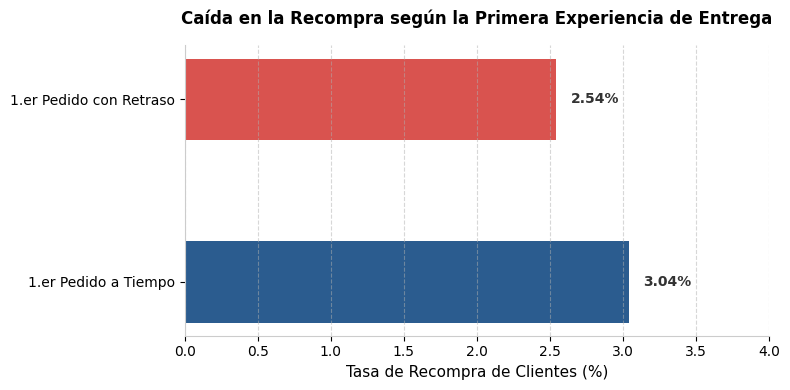

In [53]:
fig, ax = plt.subplots(figsize=(8, 4))

# Etiquetas claras de negocio
metricas = ['1.er Pedido a Tiempo', '1.er Pedido con Retraso']
valores = [df_impacto_economico['tasa_recompra_control_pct'][0], df_impacto_economico['tasa_recompra_afectada_pct'][0]]
colores = ['#2b5c8f', '#d9534f']

barras = ax.barh(metricas, valores, color=colores, height=0.45)

for barra in barras:
    ancho = barra.get_width()
    ax.text(
        ancho + 0.1, 
        barra.get_y() + barra.get_height() / 2, 
        f"{ancho:.2f}%", 
        va='center', 
        fontsize=10, 
        fontweight='bold',
        color='#333333'
    )

ax.set_xlim(0, 4)
ax.set_xlabel("Tasa de Recompra de Clientes (%)", fontsize=11)
ax.set_title("Caída en la Recompra según la Primera Experiencia de Entrega", fontsize=12, fontweight='bold', pad=15)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.grid(axis='x', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.savefig('../img/06_impacto_economico.png', dpi=300, bbox_inches='tight')
plt.show()

### Hallazgos clave e impacto financiero
- **Pérdida de clientes recurrentes:** El retraso en la primera entrega provoca que entre 40 y 50 clientes nuevos no vuelvan a comprar en la plataforma.
- **Pérdida en facturación (GMV):** Con un ticket promedio de pedido (AOV) de ~160 R$, se dejan de ingresar entre 7.500 y 8.000 R$ solo en segundas compras perdidas.
- **Inversión publicitaria desperdiciada (CAC):** Olist paga el coste de captar al usuario, pero la mala experiencia en la entrega inicial destruye la posibilidad de rentabilizarlo a través de recompras.

#### Cierre de conexión

In [54]:
# Cierre ordenado de la sesión de base de datos
con.close()
print("Sesión de DuckDB cerrada con éxito.")

Sesión de DuckDB cerrada con éxito.
